CELL 1 — Setup, Mount Drive, Extract Dataset (Auto-Detect Struktur)

In [ ]:
!pip install -q torch torchvision matplotlib seaborn scikit-learn tqdm

from google.colab import drive
drive.mount('/content/drive')

import os, zipfile

ZIP_PATH    = '/content/drive/MyDrive/dataset_reorganized.zip'
EXTRACT_DIR = '/content/BaliMask_Clean'

assert os.path.exists(ZIP_PATH), f"❌ ZIP tidak ditemukan: {ZIP_PATH}"

if not os.path.exists(EXTRACT_DIR):
    print("📦 Mengekstrak dataset dari ZIP...")
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_DIR)
    print("✅ Ekstraksi selesai.")
else:
    print("✅ Dataset sudah pernah diekstrak, lanjut.")

# ── Auto-detect struktur folder (menangani kemungkinan folder pembungkus tambahan) ──
def find_data_root(base_dir):
    """Cari folder yang langsung berisi train/valid/test."""
    if all(os.path.exists(os.path.join(base_dir, s)) for s in ['train', 'valid', 'test']):
        return base_dir
    for item in os.listdir(base_dir):
        sub = os.path.join(base_dir, item)
        if os.path.isdir(sub) and all(os.path.exists(os.path.join(sub, s)) for s in ['train', 'valid', 'test']):
            return sub
    raise FileNotFoundError(
        f"Tidak ditemukan struktur train/valid/test di dalam {base_dir}. "
        f"Isi folder: {os.listdir(base_dir)}"
    )

DATA_ROOT = find_data_root(EXTRACT_DIR)
print(f"\n✅ DATA_ROOT terdeteksi otomatis: {DATA_ROOT}")
print("Isi:", os.listdir(DATA_ROOT))
print("Kelas di train:", sorted(os.listdir(os.path.join(DATA_ROOT, 'train'))))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
📦 Mengekstrak dataset dari ZIP...
✅ Ekstraksi selesai.

✅ DATA_ROOT terdeteksi otomatis: /content/BaliMask_Clean/dataset_reorganized
Isi: ['test', 'valid', 'train']
Kelas di train: ['barong-bangkal', 'barong-ket', 'bujuh', 'dalem', 'jauk-keras', 'jauk-manis', 'keras', 'macan', 'penasar', 'sidakarya', 'telek', 'tua', 'wijil']


CELL 2 — ⚠️ VERIFIKASI GPU (WAJIB — Training Berhenti Kalau Gagal)

In [ ]:
import torch

print("=" * 60)
print("VERIFIKASI GPU")
print("=" * 60)
cuda_ok = torch.cuda.is_available()
print(f"CUDA available: {cuda_ok}")

if not cuda_ok:
    raise RuntimeError(
        "\n\n❌ GPU TIDAK AKTIF!\n"
        "Perbaiki dengan langkah ini:\n"
        "  1. Menu Runtime → Change runtime type\n"
        "  2. Hardware accelerator → pilih 'T4 GPU'\n"
        "  3. Save, lalu jalankan ulang notebook dari Cell 1 (Runtime → Run all)\n\n"
        "JANGAN lanjutkan training tanpa GPU — akan memakan waktu 10x lebih lama."
    )

print(f"✅ GPU aktif: {torch.cuda.get_device_name(0)}")
print(f"   Memory total: {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB")
print("=" * 60)

VERIFIKASI GPU
CUDA available: True
✅ GPU aktif: Tesla T4
   Memory total: 15.6 GB


CELL 3 — Config

In [ ]:
import time, copy, json, logging, warnings, random, datetime
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, WeightedRandomSampler
from torchvision import datasets, transforms, models
from torchvision.models import ConvNeXt_Tiny_Weights
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, f1_score
from tqdm.notebook import tqdm

warnings.filterwarnings("ignore")

class Config:
    DATA_ROOT    = DATA_ROOT
    OUTPUT_DIR   = '/content/drive/MyDrive/BaliMask_Clean/outputs_convnext_final'
    IMG_SIZE     = 224
    MEAN         = (0.485, 0.456, 0.406)
    STD          = (0.229, 0.224, 0.225)
    BATCH_SIZE   = 32
    NUM_EPOCHS   = 50
    LR           = 1e-4
    WEIGHT_DECAY = 1e-2
    PATIENCE     = 8
    MIN_LR       = 1e-7
    DEVICE       = 'cuda'   # sudah diverifikasi wajib GPU di Cell 2
    NUM_WORKERS  = 2
    SEED         = 42
    EMA_DECAY    = 0.999

cfg = Config()
os.makedirs(cfg.OUTPUT_DIR, exist_ok=True)
print(f"Output akan disimpan ke: {cfg.OUTPUT_DIR}")

Output akan disimpan ke: /content/drive/MyDrive/BaliMask_Clean/outputs_convnext_final


CELL 4 — Logging & Reproducibility

In [ ]:
logging.basicConfig(
    level=logging.INFO,
    format="%(asctime)s │ %(levelname)-8s │ %(message)s",
    datefmt="%Y-%m-%d %H:%M:%S",
    handlers=[
        logging.FileHandler(os.path.join(cfg.OUTPUT_DIR, "training.log")),
        logging.StreamHandler(),
    ],
    force=True,   # penting saat re-run di notebook, hindari duplikasi handler
)
logger = logging.getLogger(__name__)

def set_seed(seed=cfg.SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed()
logger.info(f"Seed fixed → {cfg.SEED}")

2026-09-28 07:23:20 │ INFO     │ Seed fixed → 42


CELL 5 — Augmentasi

In [ ]:
def build_transforms():
    train_tf = transforms.Compose([
        transforms.RandomResizedCrop(cfg.IMG_SIZE, scale=(0.7, 1.0)),
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(brightness=0.3, contrast=0.3, saturation=0.2, hue=0.05),
        transforms.RandomGrayscale(p=0.05),
        transforms.ToTensor(),
        transforms.Normalize(cfg.MEAN, cfg.STD),
        transforms.RandomErasing(p=0.1),
    ])
    eval_tf = transforms.Compose([
        transforms.Resize(int(cfg.IMG_SIZE * 1.14)),
        transforms.CenterCrop(cfg.IMG_SIZE),
        transforms.ToTensor(),
        transforms.Normalize(cfg.MEAN, cfg.STD),
    ])
    return {"train": train_tf, "valid": eval_tf, "test": eval_tf}

logger.info("Augmentasi siap: RandomResizedCrop, HFlip, Rotation±10°, ColorJitter, Grayscale, RandomErasing")
logger.info("(RandomVerticalFlip TIDAK dipakai — topeng terbalik tidak realistis secara ikonografi)")

2026-09-28 07:23:23 │ INFO     │ Augmentasi siap: RandomResizedCrop, HFlip, Rotation±10°, ColorJitter, Grayscale, RandomErasing
2026-09-28 07:23:23 │ INFO     │ (RandomVerticalFlip TIDAK dipakai — topeng terbalik tidak realistis secara ikonografi)


CELL 6 — Dataset Loading

In [ ]:
def load_datasets():
    tfs = build_transforms()
    splits = {}
    for split in ["train", "valid", "test"]:
        path = os.path.join(cfg.DATA_ROOT, split)
        splits[split] = datasets.ImageFolder(root=path, transform=tfs[split])

    assert splits["train"].classes == splits["valid"].classes == splits["test"].classes, \
        "❌ Kelas tidak sinkron antar split — cek struktur folder!"

    class_names = splits["train"].classes
    logger.info(f"Classes ({len(class_names)}): {class_names}")

    targets = np.array(splits["train"].targets)
    classes, counts = np.unique(targets, return_counts=True)
    class_weights = 1.0 / counts
    sample_weights = class_weights[targets]
    sampler = WeightedRandomSampler(
        weights=torch.from_numpy(sample_weights).float(),
        num_samples=len(sample_weights), replacement=True,
    )
    for c, cnt in zip(class_names, counts):
        logger.info(f"   {c:30s}: {cnt:5d} images")

    dataloaders = {
        "train": DataLoader(splits["train"], batch_size=cfg.BATCH_SIZE, sampler=sampler,
                            num_workers=cfg.NUM_WORKERS, pin_memory=True),
        "valid": DataLoader(splits["valid"], batch_size=cfg.BATCH_SIZE, shuffle=False,
                            num_workers=cfg.NUM_WORKERS, pin_memory=True),
        "test":  DataLoader(splits["test"],  batch_size=cfg.BATCH_SIZE, shuffle=False,
                            num_workers=cfg.NUM_WORKERS, pin_memory=True),
    }
    dataset_sizes = {s: len(splits[s]) for s in splits}
    for s, sz in dataset_sizes.items():
        logger.info(f"Dataset [{s:5s}]: {sz:5d} images")

    return dataloaders, dataset_sizes, class_names

dataloaders, dataset_sizes, class_names = load_datasets()
num_classes = len(class_names)

2026-09-28 07:23:25 │ INFO     │ Classes (13): ['barong-bangkal', 'barong-ket', 'bujuh', 'dalem', 'jauk-keras', 'jauk-manis', 'keras', 'macan', 'penasar', 'sidakarya', 'telek', 'tua', 'wijil']
2026-09-28 07:23:25 │ INFO     │    barong-bangkal                :   260 images
2026-09-28 07:23:25 │ INFO     │    barong-ket                    :   260 images
2026-09-28 07:23:25 │ INFO     │    bujuh                         :   260 images
2026-09-28 07:23:25 │ INFO     │    dalem                         :   260 images
2026-09-28 07:23:25 │ INFO     │    jauk-keras                    :   260 images
2026-09-28 07:23:25 │ INFO     │    jauk-manis                    :   260 images
2026-09-28 07:23:25 │ INFO     │    keras                         :   260 images
2026-09-28 07:23:25 │ INFO     │    macan                         :   260 images
2026-09-28 07:23:25 │ INFO     │    penasar                       :   260 images
2026-09-28 07:23:25 │ INFO     │    sidakarya                     :   260 imag

CELL 7 — Model: ConvNeXt-Tiny (V1) + EMA Wrapper

In [ ]:
def build_model(num_classes):
    model = models.convnext_tiny(weights=ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False

    in_features = model.classifier[2].in_features
    model.classifier[2] = nn.Sequential(
        nn.Linear(in_features, 256),
        nn.GELU(),
        nn.Dropout(p=0.3),
        nn.Linear(256, num_classes),
    )
    logger.info(f"ConvNeXt-Tiny (V1, torchvision) loaded │ head: {in_features} → 256 → {num_classes}")
    return model.to(cfg.DEVICE)

def unfreeze_backbone(model, last_n_stages=2):
    all_layers = list(model.features.children())
    unfreeze_from = max(0, len(all_layers) - last_n_stages)
    for i, layer in enumerate(all_layers):
        for param in layer.parameters():
            param.requires_grad = (i >= unfreeze_from)
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    total = sum(p.numel() for p in model.parameters())
    logger.info(f"Backbone unfrozen │ trainable: {trainable:,}/{total:,} ({100*trainable/total:.1f}%)")


class ModelEMA:
    """Exponential Moving Average of model weights — Polyak averaging.
    Menghasilkan model akhir yang lebih stabil, meredam noise dari batch individual."""
    def __init__(self, model, decay=0.999):
        self.ema = copy.deepcopy(model).eval()
        for p in self.ema.parameters():
            p.requires_grad_(False)
        self.decay = decay

    def update(self, model):
        with torch.no_grad():
            for ema_p, p in zip(self.ema.state_dict().values(), model.state_dict().values()):
                if ema_p.dtype.is_floating_point:
                    ema_p.mul_(self.decay).add_(p.detach(), alpha=1 - self.decay)
                else:
                    ema_p.copy_(p)


class EarlyStopping:
    def __init__(self, patience=cfg.PATIENCE, delta=1e-4):
        self.patience, self.delta = patience, delta
        self.counter, self.best_loss, self.stop = 0, None, False

    def __call__(self, val_loss):
        if self.best_loss is None or val_loss < self.best_loss - self.delta:
            self.best_loss, self.counter = val_loss, 0
        else:
            self.counter += 1
            logger.info(f"EarlyStopping counter: {self.counter}/{self.patience}")
            if self.counter >= self.patience:
                self.stop = True
        return self.stop


model = build_model(num_classes)
ema = ModelEMA(model, decay=cfg.EMA_DECAY)
print(f"✅ Model & EMA siap (decay={cfg.EMA_DECAY})")

Downloading: "https://download.pytorch.org/models/convnext_tiny-983f1562.pth" to /root/.cache/torch/hub/checkpoints/convnext_tiny-983f1562.pth


100%|██████████| 109M/109M [00:00<00:00, 176MB/s]
2026-09-28 07:23:31 │ INFO     │ ConvNeXt-Tiny (V1, torchvision) loaded │ head: 768 → 256 → 13


✅ Model & EMA siap (decay=0.999)


CELL 8 — Auto-Resume: Cek Checkpoint Sebelumnya

Ini cell paling penting untuk anti-kehilangan-progress. Checkpoint latest_checkpoint.pth disimpan setiap epoch (bukan cuma yang terbaik), jadi resume selalu tepat dari titik terakhir — tidak peduli disconnect terjadi kapan pun.

In [ ]:
LATEST_CKPT_PATH = os.path.join(cfg.OUTPUT_DIR, "latest_checkpoint.pth")
BEST_CKPT_PATH   = os.path.join(cfg.OUTPUT_DIR, "best_model.pth")

start_epoch = 1
history = {"train_loss": [], "valid_loss": [], "train_acc": [], "valid_acc": []}
best_val_loss = float("inf")
early_stop_counter = 0
phase2_triggered = False

if os.path.exists(LATEST_CKPT_PATH):
    print(f"📂 Checkpoint ditemukan: {LATEST_CKPT_PATH}")
    ckpt = torch.load(LATEST_CKPT_PATH, map_location=cfg.DEVICE, weights_only=False)

    model.load_state_dict(ckpt['model_state_dict'])
    ema.ema.load_state_dict(ckpt['ema_state_dict'])
    start_epoch          = ckpt['epoch'] + 1
    history               = ckpt['history']
    best_val_loss          = ckpt['best_val_loss']
    early_stop_counter     = ckpt.get('early_stop_counter', 0)
    phase2_triggered        = ckpt.get('phase2_triggered', False)

    print(f"✅ RESUME dari epoch {start_epoch}")
    print(f"   Best val_loss sejauh ini: {best_val_loss:.4f}")
    print(f"   Early stop counter: {early_stop_counter}/{cfg.PATIENCE}")
    print(f"   Fase 2 sudah aktif: {phase2_triggered}")

    if phase2_triggered:
        unfreeze_backbone(model, last_n_stages=2)
else:
    print("🆕 Tidak ada checkpoint — training dimulai dari epoch 1 (resep bersih, konsisten)")

print(f"\n▶️  Training akan berjalan dari epoch {start_epoch} sampai {cfg.NUM_EPOCHS}")

🆕 Tidak ada checkpoint — training dimulai dari epoch 1 (resep bersih, konsisten)

▶️  Training akan berjalan dari epoch 1 sampai 50


CELL 9 — Training Loop (Resep Final, Auto-Save Setiap Epoch)

In [ ]:
def train_model(model, ema, dataloaders, dataset_sizes, num_classes,
                start_epoch, history, best_val_loss, early_stop_counter, phase2_triggered):

    criterion = nn.CrossEntropyLoss(label_smoothing=0.1)

    if phase2_triggered:
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                lr=cfg.LR * 0.1, weight_decay=cfg.WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.NUM_EPOCHS - 10, eta_min=cfg.MIN_LR)
    else:
        optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                lr=cfg.LR, weight_decay=cfg.WEIGHT_DECAY)
        scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.NUM_EPOCHS, eta_min=cfg.MIN_LR)

    early_stop = EarlyStopping()
    early_stop.counter = early_stop_counter
    early_stop.best_loss = best_val_loss if best_val_loss != float("inf") else None

    best_weights = copy.deepcopy(model.state_dict())
    training_start = time.time()

    print("🚀 TRAINING DIMULAI (resep final: EMA aktif, tanpa MixUp/LLRD)")
    print("=" * 70)

    for epoch in range(start_epoch, cfg.NUM_EPOCHS + 1):
        epoch_start = time.time()

        if epoch == 11 and not phase2_triggered:
            unfreeze_backbone(model, last_n_stages=2)
            optimizer = optim.AdamW(filter(lambda p: p.requires_grad, model.parameters()),
                                    lr=cfg.LR * 0.1, weight_decay=cfg.WEIGHT_DECAY)
            scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=cfg.NUM_EPOCHS - 10, eta_min=cfg.MIN_LR)
            phase2_triggered = True
            print("\n🔓 FASE 2 DIBUKA — fine-tuning 2 stage terakhir backbone\n")

        for phase in ["train", "valid"]:
            model.train() if phase == "train" else model.eval()
            running_loss, running_corrects, seen = 0.0, 0, 0

            emoji = "🏋️ " if phase == "train" else "🔍 "
            pbar = tqdm(dataloaders[phase],
                       desc=f"{emoji}Epoch {epoch:2d}/{cfg.NUM_EPOCHS} [{phase:5s}]",
                       leave=False, colour="blue" if phase == "train" else "green")

            for inputs, labels in pbar:
                inputs, labels = inputs.to(cfg.DEVICE), labels.to(cfg.DEVICE)
                optimizer.zero_grad()
                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    loss = criterion(outputs, labels)
                    preds = outputs.argmax(dim=1)
                    if phase == "train":
                        loss.backward()
                        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                        optimizer.step()
                        ema.update(model)

                batch_size = inputs.size(0)
                running_loss += loss.item() * batch_size
                running_corrects += (preds == labels).sum().item()
                seen += batch_size
                pbar.set_postfix({"loss": f"{running_loss/seen:.4f}", "acc": f"{running_corrects/seen*100:.1f}%"})

            pbar.close()
            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects / dataset_sizes[phase]
            history[f"{phase}_loss"].append(epoch_loss)
            history[f"{phase}_acc"].append(epoch_acc)

            if phase == "valid":
                epoch_time = time.time() - epoch_start
                eta_str = str(datetime.timedelta(seconds=int(epoch_time * (cfg.NUM_EPOCHS - epoch))))
                elapsed_str = str(datetime.timedelta(seconds=int(time.time() - training_start)))
                improved = epoch_loss < best_val_loss
                marker = "🟢" if improved else "⚪"

                print(f"{marker} Epoch {epoch:3d}/{cfg.NUM_EPOCHS} "
                     f"│ Train: loss={history['train_loss'][-1]:.4f} acc={history['train_acc'][-1]*100:.2f}% "
                     f"│ Val: loss={epoch_loss:.4f} acc={epoch_acc*100:.2f}% "
                     f"│ ⏱ {epoch_time:.0f}s (total {elapsed_str}, ETA {eta_str})")

                logger.info(f"Epoch {epoch:3d}/{cfg.NUM_EPOCHS} │ Val Loss: {epoch_loss:.4f} Acc: {epoch_acc*100:.2f}%")

                if improved:
                    best_val_loss = epoch_loss
                    best_weights = copy.deepcopy(model.state_dict())
                    torch.save({
                        "epoch": epoch, "model_state_dict": best_weights,
                        "ema_state_dict": ema.ema.state_dict(),
                        "val_loss": best_val_loss, "class_names": class_names,
                    }, BEST_CKPT_PATH)
                    print(f"   💾 BEST checkpoint tersimpan (val_loss: {best_val_loss:.4f})")

                # ── SELALU simpan checkpoint terbaru, setiap epoch, apapun hasilnya ──
                # Ini yang membuat resume selalu presisi walau disconnect kapan saja
                torch.save({
                    "epoch": epoch,
                    "model_state_dict": model.state_dict(),
                    "ema_state_dict": ema.ema.state_dict(),
                    "history": history,
                    "best_val_loss": best_val_loss,
                    "early_stop_counter": early_stop.counter,
                    "phase2_triggered": phase2_triggered,
                    "class_names": class_names,
                }, LATEST_CKPT_PATH)

                if early_stop(epoch_loss):
                    print(f"\n🛑 EARLY STOPPING di epoch {epoch}")
                    logger.info(f"Early stopping triggered at epoch {epoch}.")
                    model.load_state_dict(best_weights)
                    return model, ema, history
        scheduler.step()

    model.load_state_dict(best_weights)
    total_time = str(datetime.timedelta(seconds=int(time.time() - training_start)))
    print(f"\n✅ TRAINING SELESAI — total waktu sesi ini: {total_time}")
    return model, ema, history


model, ema, history = train_model(
    model, ema, dataloaders, dataset_sizes, num_classes,
    start_epoch=start_epoch, history=history,
    best_val_loss=best_val_loss, early_stop_counter=early_stop_counter,
    phase2_triggered=phase2_triggered,
)

🚀 TRAINING DIMULAI (resep final: EMA aktif, tanpa MixUp/LLRD)


🏋️ Epoch  1/50 [train]:   0%|          | 0/106 [00:00<?, ?it/s]

🔍 Epoch  1/50 [valid]:   0%|          | 0/23 [00:00<?, ?it/s]

2026-09-24 12:43:33 │ INFO     │ Epoch   1/50 │ Val Loss: 1.8750 Acc: 85.29%


🟢 Epoch   1/50 │ Train: loss=2.2503 acc=52.60% │ Val: loss=1.8750 acc=85.29% │ ⏱ 65s (total 0:01:04, ETA 0:52:48)
   💾 BEST checkpoint tersimpan (val_loss: 1.8750)


🏋️ Epoch  2/50 [train]:   0%|          | 0/106 [00:00<?, ?it/s]

... (207 outputs left out)

2026-09-24 13:29:54 │ INFO     │ Epoch  50/50 │ Val Loss: 0.5749 Acc: 99.72%


🟢 Epoch  50/50 │ Train: loss=0.5747 acc=99.88% │ Val: loss=0.5749 acc=99.72% │ ⏱ 57s (total 0:47:25, ETA 0:00:00)
   💾 BEST checkpoint tersimpan (val_loss: 0.5749)


2026-09-24 13:29:55 │ INFO     │ EarlyStopping counter: 2/8



✅ TRAINING SELESAI — total waktu sesi ini: 0:47:26


Cell Recovery

In [ ]:
# ── RECOVERY: muat hasil training dari Drive, TANPA training ulang ──
BEST_CKPT_PATH   = os.path.join(cfg.OUTPUT_DIR, "best_model.pth")
LATEST_CKPT_PATH = os.path.join(cfg.OUTPUT_DIR, "latest_checkpoint.pth")

for p in (BEST_CKPT_PATH, LATEST_CKPT_PATH):
    assert os.path.exists(p), f"❌ Tidak ditemukan: {p}"

best = torch.load(BEST_CKPT_PATH, map_location=cfg.DEVICE, weights_only=False)
model.load_state_dict(best["model_state_dict"])
ema.ema.load_state_dict(best["ema_state_dict"])
model.eval(); ema.ema.eval()

last = torch.load(LATEST_CKPT_PATH, map_location="cpu", weights_only=False)
history = last["history"]

print(f"✅ Bobot terbaik dimuat: epoch {best['epoch']} (val_loss {best['val_loss']:.4f})")
print(f"✅ History dimuat: {len(history['train_loss'])} epoch")

✅ Bobot terbaik dimuat: epoch 50 (val_loss 0.5749)
✅ History dimuat: 50 epoch


CELL 10 — Training Curves

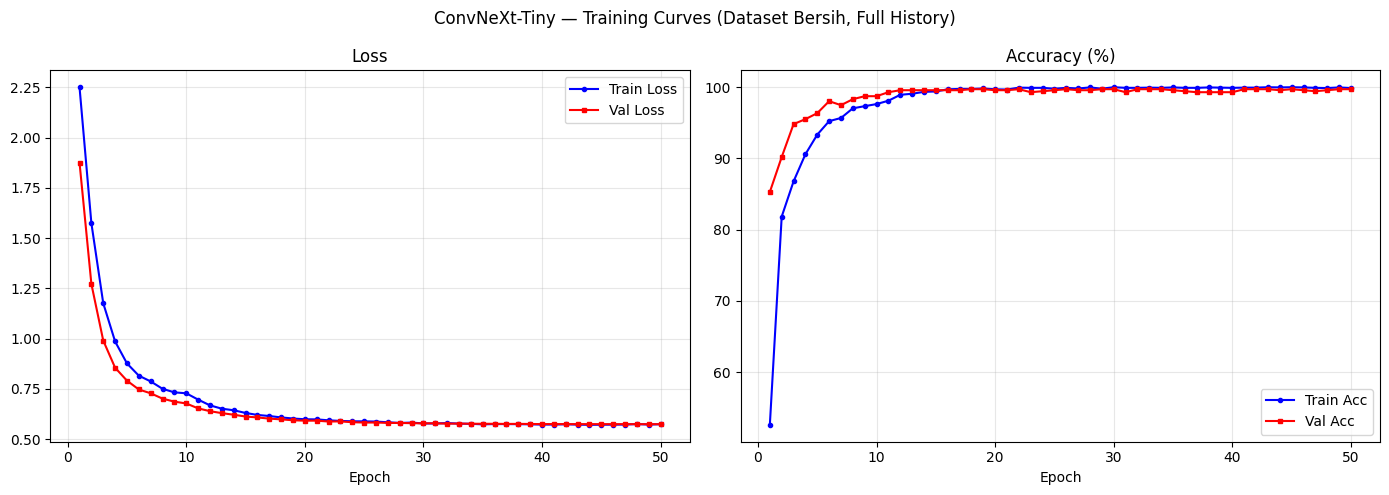

In [ ]:
def plot_training_curves(history):
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    epochs = range(1, len(history["train_loss"]) + 1)

    axes[0].plot(epochs, history["train_loss"], "b-o", ms=3, label="Train Loss")
    axes[0].plot(epochs, history["valid_loss"], "r-s", ms=3, label="Val Loss")
    axes[0].set_title("Loss"); axes[0].set_xlabel("Epoch"); axes[0].legend(); axes[0].grid(alpha=0.3)

    axes[1].plot(epochs, [a*100 for a in history["train_acc"]], "b-o", ms=3, label="Train Acc")
    axes[1].plot(epochs, [a*100 for a in history["valid_acc"]], "r-s", ms=3, label="Val Acc")
    axes[1].set_title("Accuracy (%)"); axes[1].set_xlabel("Epoch"); axes[1].legend(); axes[1].grid(alpha=0.3)

    plt.suptitle("ConvNeXt-Tiny — Training Curves (Dataset Bersih, Full History)")
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.OUTPUT_DIR, "training_curves.png"), dpi=150)
    plt.show()

plot_training_curves(history)

CELL 11 — Evaluasi: Model Biasa vs EMA (Dibandingkan, Bukan Diasumsikan)

In [ ]:
def evaluate(eval_model, dataloader, class_names, label=""):
    eval_model.eval()
    all_labels, all_preds = [], []
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(cfg.DEVICE)
            outputs = eval_model(inputs)
            preds = torch.softmax(outputs, dim=1).argmax(dim=1)
            all_labels.extend(labels.numpy())
            all_preds.extend(preds.cpu().numpy())
    acc = accuracy_score(all_labels, all_preds) * 100
    f1  = f1_score(all_labels, all_preds, average="macro") * 100
    print(f"[{label:12s}] Test Accuracy: {acc:.2f}% │ F1-Macro: {f1:.2f}%")
    return np.array(all_labels), np.array(all_preds), acc, f1

print("=" * 60)
print("PERBANDINGAN: Model Biasa vs Model EMA")
print("=" * 60)
y_true, y_pred_reg, acc_reg, f1_reg = evaluate(model, dataloaders["test"], class_names, "Model Biasa")
_,      y_pred_ema, acc_ema, f1_ema = evaluate(ema.ema, dataloaders["test"], class_names, "Model EMA")
print("=" * 60)

use_ema = acc_ema > acc_reg
final_model = ema.ema if use_ema else model
y_pred       = y_pred_ema if use_ema else y_pred_reg
final_acc    = acc_ema if use_ema else acc_reg
final_f1     = f1_ema if use_ema else f1_reg

print(f"\n🏆 Model TERBAIK yang dipakai: {'EMA' if use_ema else 'Biasa'} "
     f"(Acc: {final_acc:.2f}%, F1-Macro: {final_f1:.2f}%)")

# Simpan model final yang terpilih
torch.save({
    "model_state_dict": final_model.state_dict(),
    "class_names": class_names,
    "test_accuracy": final_acc,
    "test_f1_macro": final_f1,
    "source": "ema" if use_ema else "regular",
}, os.path.join(cfg.OUTPUT_DIR, "final_model.pth"))

report = classification_report(y_true, y_pred, target_names=class_names, digits=4)
print(f"\n{report}")
with open(os.path.join(cfg.OUTPUT_DIR, "classification_report_test.txt"), "w") as f:
    f.write(f"Model terpilih: {'EMA' if use_ema else 'Biasa'}\n\n{report}")

PERBANDINGAN: Model Biasa vs Model EMA
[Model Biasa ] Test Accuracy: 100.00% │ F1-Macro: 100.00%
[Model EMA   ] Test Accuracy: 100.00% │ F1-Macro: 100.00%

🏆 Model TERBAIK yang dipakai: Biasa (Acc: 100.00%, F1-Macro: 100.00%)

                precision    recall  f1-score   support

barong-bangkal     1.0000    1.0000    1.0000        25
    barong-ket     1.0000    1.0000    1.0000        25
         bujuh     1.0000    1.0000    1.0000        25
         dalem     1.0000    1.0000    1.0000        25
    jauk-keras     1.0000    1.0000    1.0000        25
    jauk-manis     1.0000    1.0000    1.0000        25
         keras     1.0000    1.0000    1.0000        25
         macan     1.0000    1.0000    1.0000        25
       penasar     1.0000    1.0000    1.0000        25
     sidakarya     1.0000    1.0000    1.0000        25
         telek     1.0000    1.0000    1.0000        26
           tua     1.0000    1.0000    1.0000        26
         wijil     1.0000    1.0000    1.000

CELL 12 — Confusion Matrix

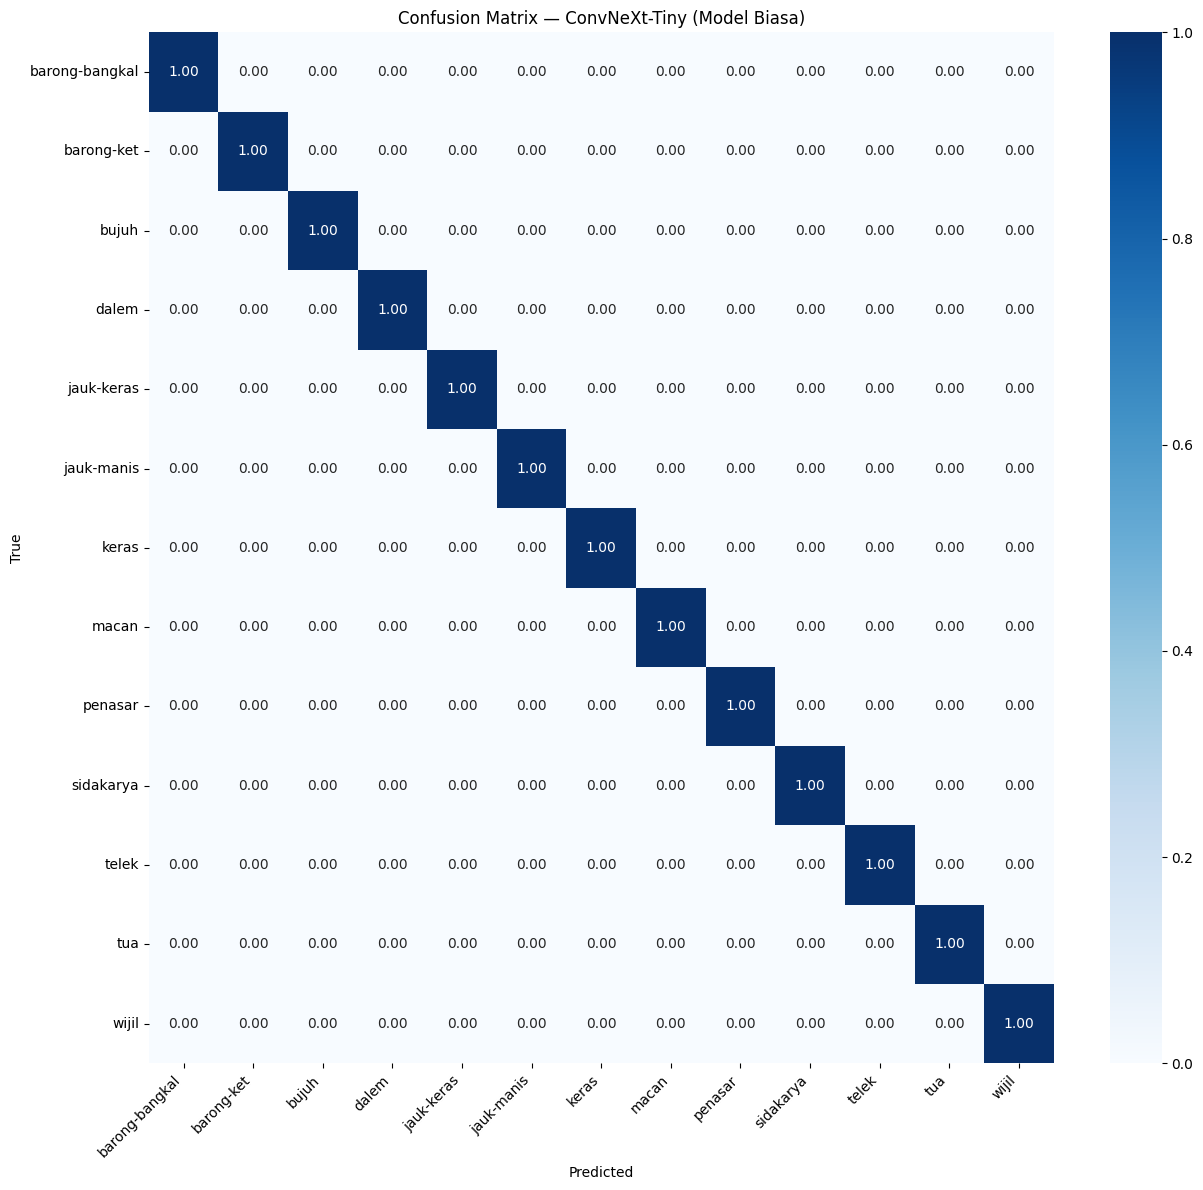

In [ ]:
def plot_confusion_matrix(y_true, y_pred, class_names):
    cm = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)

    fig, ax = plt.subplots(figsize=(max(8,len(class_names)), max(6,len(class_names)-1)))
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues",
               xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"Confusion Matrix — ConvNeXt-Tiny (Model {'EMA' if use_ema else 'Biasa'})")
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig(os.path.join(cfg.OUTPUT_DIR, "confusion_matrix.png"), dpi=150)
    plt.show()

plot_confusion_matrix(y_true, y_pred, class_names)

CELL 13 — Perbandingan Final vs Model Lama

In [ ]:
print("=" * 70)
print("PERBANDINGAN AKHIR: Dataset Lama (kolase) vs Dataset Baru (bersih)")
print("=" * 70)
print(f"{'Metrik':<25} {'Model Lama':>15} {'Model Baru':>15}")
print("-" * 70)
print(f"{'Test Accuracy':<25} {'96.55%':>15} {f'{final_acc:.2f}%':>15}")
print(f"{'F1-Macro':<25} {'96.61%':>15} {f'{final_f1:.2f}%':>15}")
print(f"{'Model dipakai':<25} {'ConvNeXt (kolase)':>15} {('EMA' if use_ema else 'Biasa'):>15}")
print("=" * 70)

comparison = {
    "model_lama": {"accuracy": 96.55, "f1_macro": 96.61, "dataset": "mengandung kolase multi-topeng"},
    "model_baru": {
        "accuracy": round(final_acc, 2), "f1_macro": round(final_f1, 2),
        "dataset": "bersih, per-class, tanpa kolase",
        "model_source": "ema" if use_ema else "regular",
        "total_epochs_trained": len(history["train_loss"]),
    },
}
with open(os.path.join(cfg.OUTPUT_DIR, "comparison_final.json"), "w") as f:
    json.dump(comparison, f, indent=2, ensure_ascii=False)

print(f"\n✅ Semua hasil tersimpan di: {cfg.OUTPUT_DIR}")
print("   - final_model.pth              (model terbaik siap pakai)")
print("   - best_model.pth                (checkpoint val_loss terbaik)")
print("   - latest_checkpoint.pth          (checkpoint resume terakhir)")
print("   - training_curves.png")
print("   - confusion_matrix.png")
print("   - classification_report_test.txt")
print("   - comparison_final.json")
print("   - training.log")

PERBANDINGAN AKHIR: Dataset Lama (kolase) vs Dataset Baru (bersih)
Metrik                         Model Lama      Model Baru
----------------------------------------------------------------------
Test Accuracy                      96.55%         100.00%
F1-Macro                           96.61%         100.00%
Model dipakai             ConvNeXt (kolase)           Biasa

✅ Semua hasil tersimpan di: /content/drive/MyDrive/BaliMask_Clean/outputs_convnext_final
   - final_model.pth              (model terbaik siap pakai)
   - best_model.pth                (checkpoint val_loss terbaik)
   - latest_checkpoint.pth          (checkpoint resume terakhir)
   - training_curves.png
   - confusion_matrix.png
   - classification_report_test.txt
   - comparison_final.json
   - training.log
